In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/Walmart DataSet.csv')


In [69]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [70]:
df.shape

(6435, 8)

In [71]:
df.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


In [72]:
df.duplicated().sum()

np.int64(0)

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [74]:
# change date from object to datetime format
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

In [75]:
# checking for null values
print(df.isnull().sum())

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64


In [76]:
df = df.sort_values(['Store', 'Date'])
store_sales = df.groupby('Store')['Weekly_Sales'].sum().sort_values(ascending=False)
store_sales.head()

,Weekly_Sales
Store,
20,3.013978e+08
4,2.995440e+08
14,2.889999e+08
13,2.865177e+08
2,2.753824e+08


In [78]:
# Sorting  and finding top 5 and worst 5 stores
store_sales = df.groupby('Store')['Weekly_Sales'].sum().sort_values( ascending=False )
print('Best 5 stores:\n',store_sales.head(5))
print('Worst 5 stores:\n',store_sales.tail(5))

Best 5 stores:
 Store
20    3.013978e+08
4     2.995440e+08
14    2.889999e+08
13    2.865177e+08
2     2.753824e+08
Name: Weekly_Sales, dtype: float64
Worst 5 stores:
 Store
38    55159626.42
36    53412214.97
5     45475688.90
44    43293087.84
33    37160221.96
Name: Weekly_Sales, dtype: float64


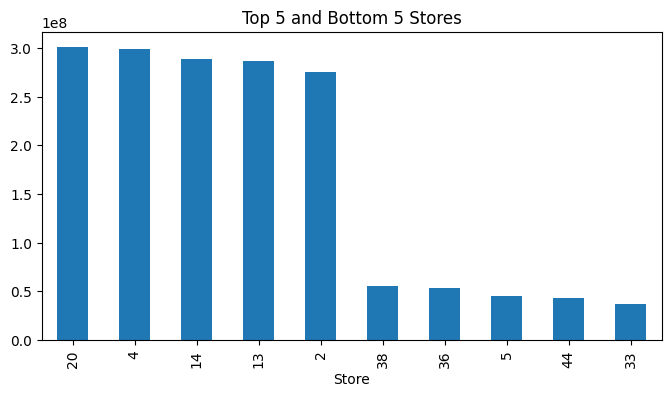

In [79]:
# best 5 and worst 5 stores
pd.concat([store_sales.head(5), store_sales.tail(5)]).plot(kind='bar', figsize=(8,4), title='Top 5 and Bottom 5 Stores')
plt.show()

In [80]:
# correlation of sales with unemployment for each store
unemp = df.groupby('Store').apply(lambda x: x['Weekly_Sales'].corr(x['Unemployment'])).sort_values()
print(unemp.head(5))
print(unemp.tail(5))

Store
38   -0.785290
44   -0.780076
39   -0.384681
42   -0.356355
41   -0.350630
dtype: float64
Store
30    0.201862
14    0.210786
21    0.218367
35    0.483865
36    0.833734
dtype: float64


/tmp/ipykernel_3006/3724031969.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  unemp = df.groupby('Store').apply(lambda x: x['Weekly_Sales'].corr(x['Unemployment'])).sort_values()


In [81]:
# find correlation to see what affects weekly sales
df[['Weekly_Sales','Temperature','Fuel_Price','CPI','Unemployment']].corr()['Weekly_Sales']

,Weekly_Sales
Weekly_Sales,1.000000
Temperature,-0.063810
Fuel_Price,0.009464
CPI,-0.072634
Unemployment,-0.106176


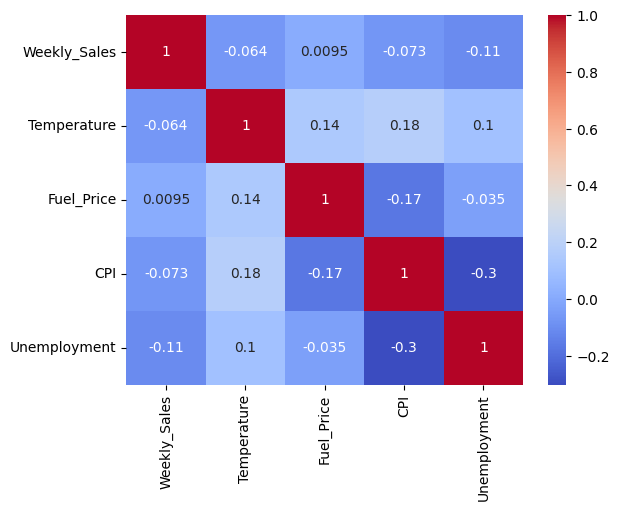

In [83]:
#Heatmap of corr
sns.heatmap(df[['Weekly_Sales','Temperature','Fuel_Price','CPI','Unemployment']].corr(), annot=True, cmap='coolwarm')
plt.show()

<Axes: title={'center': 'Mean of Weekly Sales by Month'}, xlabel='Month'>

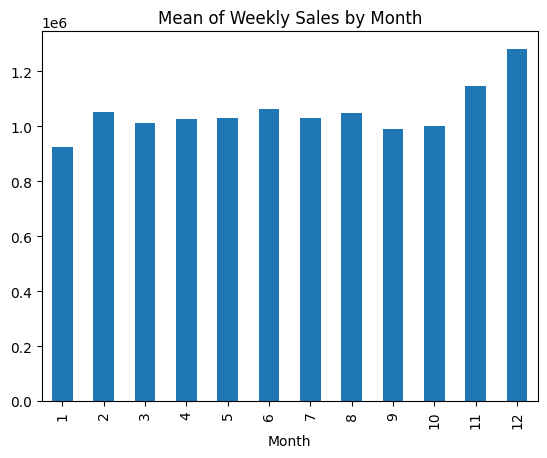

In [84]:
# Seasonality: average sales by month
df['Month'] = df['Date'].dt.month
df.groupby('Month')['Weekly_Sales'].mean().plot(kind='bar', title='Mean of Weekly Sales by Month')

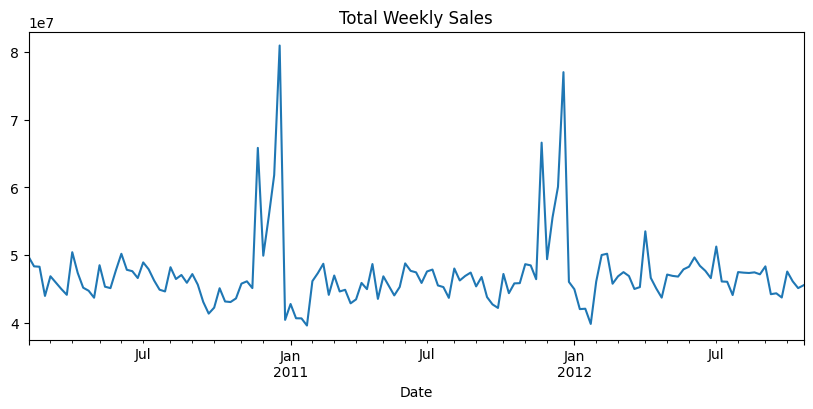

In [77]:
# total sales across all stores week by week
df.groupby('Date')['Weekly_Sales'].sum().plot(figsize=(10,4), title='Total Weekly Sales')
plt.show()

In [87]:
# top 10 weeks by total sales
top_weeks = df.groupby('Date')['Weekly_Sales'].sum().sort_values(ascending=False).head(10)
print(top_weeks)

Date
2010-12-24    80931415.60
2011-12-23    76998241.31
2011-11-25    66593605.26
2010-11-26    65821003.24
2010-12-17    61820799.85
2011-12-16    60085695.94
2010-12-10    55666770.39
2011-12-09    55561147.70
2012-04-06    53502315.87
2012-07-06    51253021.88
Name: Weekly_Sales, dtype: float64


In [85]:
# Figuring out if holiday weeks sell more
df.groupby('Holiday_Flag')['Weekly_Sales'].mean()

,Weekly_Sales
Holiday_Flag,
0,1.041256e+06
1,1.122888e+06


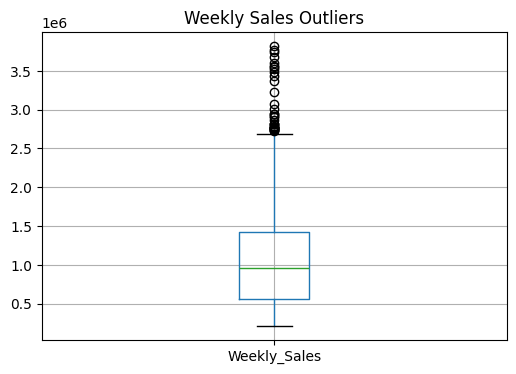

In [86]:
#finding out outliers
import matplotlib.pyplot as plt
df.boxplot(column='Weekly_Sales', figsize=(6,4))
plt.title('Weekly Sales Outliers')
plt.show()

In [88]:
# checking outliers with the IQR rule
q1 = df['Weekly_Sales'].quantile(0.25)
q3 = df['Weekly_Sales'].quantile(0.75)
iqr = q3 - q1
outliers = df[(df['Weekly_Sales'] > q3 + 1.5*iqr) | (df['Weekly_Sales'] < q1 - 1.5*iqr)]
print(len(outliers))
print(outliers['Date'].dt.month.value_counts())

34
Date
12    25
11     9
Name: count, dtype: int64


outliers are mostly in holiday seasons so they are real data and we must keep them

In [95]:
# f. the gap between best and worst store
print('Best :',store_sales.iloc[0])
print('Worst :',store_sales.iloc[-1])
print('Best store has',(store_sales.iloc[0] / store_sales.iloc[-1]).round(2),'times sales than the worst')

Best : 301397792.46
Worst : 37160221.96
Best store has 8.11 times sales than the worst


Forecast

In [100]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_percentage_error
import warnings
warnings.filterwarnings('ignore')

In [101]:
results = []
forecasts = {}

for s in sorted(df['Store'].unique()):
    ts = df[df['Store'] == s].set_index('Date')['Weekly_Sales'].asfreq('W-FRI')
    train, test = ts[:-12], ts[-12:]

    # testing on the last 12 weeks first
    m = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=52).fit()
    results.append((s, mean_absolute_percentage_error(test, m.forecast(12))))

    # refitting on everything to predict the next 12 weeks
    final = ExponentialSmoothing(ts, trend='add', seasonal='add', seasonal_periods=52).fit()
    forecasts[s] = final.forecast(12)

In [102]:
#validate forcast
res = pd.DataFrame(results, columns=['Store', 'MAPE'])
print(res['MAPE'].mean())
print(res.sort_values('MAPE').head())
print(res.sort_values('MAPE').tail())

0.042463873251170105
    Store      MAPE
29     30  0.014020
36     37  0.017138
2       3  0.019738
33     34  0.020217
11     12  0.020861
    Store      MAPE
32     33  0.066751
28     29  0.073208
22     23  0.087821
34     35  0.170062
13     14  0.199724


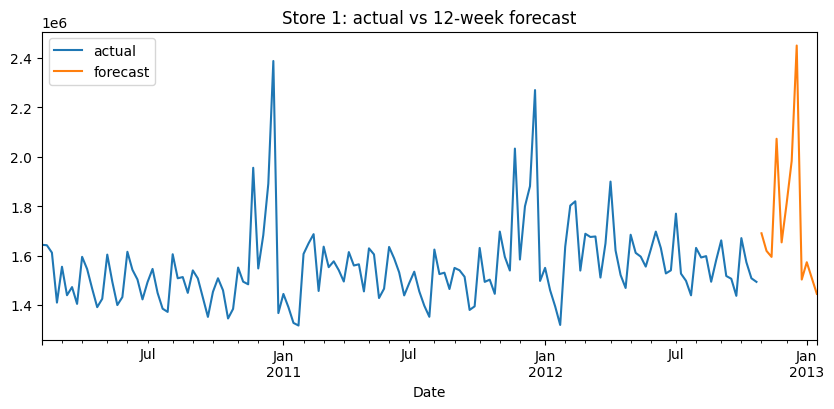

In [103]:
fc = pd.DataFrame(forecasts)
fc.to_csv('forecast_12_weeks.csv')

# store 1 history and forecast together
ts1 = df[df['Store'] == 1].set_index('Date')['Weekly_Sales']
ts1.plot(figsize=(10,4), label='actual')
fc[1].plot(label='forecast')
plt.legend()
plt.title('Store 1: actual vs 12-week forecast')
plt.show()